# 09. Ba hàm mất mát trên hai neo

Sổ tay notebook 05 thử ba hàm mất mát nhưng chỉ trên neo A. Sổ tay notebook 07 bổ sung ô Huber trên neo B. Lưới hai neo nhân ba hàm mất mát vì thế còn trống đúng một ô: neo B với hàm sai số tuyệt đối.

Câu hỏi cụ thể: khi đã dùng neo quan sát thật, việc huấn luyện trực tiếp trên hàm sai số tuyệt đối còn mang lại lợi ích gì so với huấn luyện trên sai số bình phương hoặc Huber. Tuần 2 cho thấy chỉ số kỹ năng tính theo sai số tuyệt đối là đại lượng quyết định kết luận, nên việc tối ưu trực tiếp đại lượng đó là phép thử đối chứng bắt buộc trước khi tuyên bố neo B là nguồn cải thiện chính.

Thiết kế: sáu ô gồm neo A và neo B nhân với ba hàm mất mát, mỗi ô ba hạt giống. Năm ô đã có sẵn trong các lần chạy tuần 2 nên được đọc lại; chỉ ô neo B với hàm sai số tuyệt đối cần huấn luyện mới. Chi phí ước lượng khoảng năm phút.

Phép dừng sớm trong mã dùng chung luôn theo đúng hàm mất mát đang huấn luyện, nên phép so sánh giữa ba hàm không bị thiên lệch bởi tiêu chí chọn mô hình.

> **Vị trí trong chuỗi tái lập:** notebook 09 trên tổng số 31. Thứ tự chạy và sơ đồ phụ thuộc nằm trong `README.md`.
>
> **Cần chạy trước:** 03-Tien_xu_ly_va_thuc_nghiem_chinh, 04-Bon_phuong_an_neo, 05-Ham_mat_mat_Huber, 07-Huber_va_neo_B.
>
> **Thư mục kết quả:** `Output/processed/w3_16_ba_ham_mat_mat_hai_neo/`.
>
> **Mã định danh nội bộ:** `W3_16`. Mã này còn xuất hiện trong tên khóa JSON, tên hình và nhật ký chạy; nó được giữ nguyên để không phá phép đối chiếu chéo và mã băm của bản khai báo trước.

## 1. Tham số và đường dẫn

In [1]:
#@title Tham số chạy { display-mode: "form" }
PROJECT_DIR = "/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4"  #@param {type:"string"}
READ_TAG = "chot"  #@param {type:"string"}
RUN_TAG = "w3_16_ba_ham_mat_mat_hai_neo"  #@param {type:"string"}
HUBER_DELTA = 1.0  #@param {type:"number"}
NGUON_HAM_MAT_MAT = "bo_sung_06_huber"  #@param {type:"string"}
NGUON_NEO = "bo_sung_04_neo_abcd"  #@param {type:"string"}
NGUON_HUBER_NEO_B = "bo_sung_14_huber_neo_b"  #@param {type:"string"}
N_BOOT = 5000  #@param {type:"integer"}
SEQ_LEN = 36     #@param {type:"integer"}
PRED_LEN = 12    #@param {type:"integer"}
N_SEEDS = 3      #@param {type:"integer"}
EPOCHS = 60      #@param {type:"integer"}
PATIENCE = 10    #@param {type:"integer"}
BATCH = 128      #@param {type:"integer"}
LR = 1e-3        #@param {type:"number"}

import os, sys, json, time, random, datetime, platform, importlib, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
else:
    PROJECT_DIR = os.environ.get("P12_PROJECT", "./AIO2026_Conquer_M4_DLinear_NLinear_Slot4")

PROJECT = Path(PROJECT_DIR)
OUT = PROJECT / "Output"
# Đọc dữ liệu đã tiền xử lý của lần chạy chốt, ghi kết quả sang một thư mục con riêng.
PROC = OUT / "processed" / READ_TAG
RUN_DIR = OUT / "processed" / RUN_TAG
RUNS = RUN_DIR / "runs"
FIGS = RUN_DIR / "figures"
LOGS = RUN_DIR / "logs"
for d in (RUN_DIR, RUNS, FIGS, LOGS):
    d.mkdir(parents=True, exist_ok=True)

assert (PROC / "meta.json").exists(), (
    "Không thấy dữ liệu đã tiền xử lý trong " + str(PROC) +
    ". Hãy chạy notebook 03-Tien_xu_ly_va_thuc_nghiem_chinh trước.")
meta = json.loads((PROC / "meta.json").read_text())
channels = meta["channels"]
EPS = 1e-8

print("Thư mục đọc :", PROC)
print("Thư mục ghi :", RUN_DIR)
print("Số kênh     :", len(channels), "| ngưỡng cắt sigma của lần chạy nguồn:", meta["clip_sigma"])


Mounted at /content/drive
Thư mục đọc : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot
Thư mục ghi : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_16_ba_ham_mat_mat_hai_neo
Số kênh     : 37 | ngưỡng cắt sigma của lần chạy nguồn: 0.0


In [2]:
REQUIRED = {"numpy": "1.24.0", "torch": "2.0.0", "matplotlib": "3.7.0", "scipy": "1.10.0"}


def ver_tuple(v):
    out = []
    for part in str(v).split(".")[:3]:
        digits = "".join(ch for ch in part if ch.isdigit())
        out.append(int(digits) if digits else 0)
    return tuple(out + [0] * (3 - len(out)))


missing = []
for name, floor in REQUIRED.items():
    try:
        mod = importlib.import_module(name)
        if ver_tuple(mod.__version__) < ver_tuple(floor):
            missing.append(name + ">=" + floor)
    except ImportError:
        missing.append(name + ">=" + floor)

if missing:
    print("Cài bổ sung:", " ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + missing, check=True)

import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

ENV = {
    "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    "run_tag": RUN_TAG,
    "read_tag": READ_TAG,
    "python": platform.python_version(),
    "numpy": np.__version__,
    "torch": torch.__version__,
    "matplotlib": matplotlib.__version__,
    "scipy": scipy.__version__,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
}
stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
(LOGS / ("env_" + stamp + ".json")).write_text(json.dumps(ENV, ensure_ascii=False, indent=2))
for k, v in ENV.items():
    print(k.ljust(12), v)


timestamp    2026-10-14T18:22:40
run_tag      w3_16_ba_ham_mat_mat_hai_neo
read_tag     chot
python       3.13.15
numpy        2.1.3
torch        2.11.0+cu130
matplotlib   3.10.0
scipy        1.16.3
gpu          Tesla T4


In [3]:
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#000000"]

matplotlib.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "legend.frameon": False,
    "lines.linewidth": 1.4,
    "axes.prop_cycle": matplotlib.cycler(color=PALETTE),
    "figure.constrained_layout.use": True,
})


def luu_hinh(fig, ten):
    duong = FIGS / ten
    fig.savefig(duong)
    print("Đã lưu", duong)
    return duong


print("Đã đặt quy ước trình bày hình")


Đã đặt quy ước trình bày hình


## 2. Mô hình, dữ liệu và hàm huấn luyện

In [4]:
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def moving_avg(x, kernel_size=25):
    front = x[:, :1, :].repeat(1, (kernel_size - 1) // 2, 1)
    end = x[:, -1:, :].repeat(1, kernel_size - (kernel_size - 1) // 2 - 1, 1)
    xp = torch.cat([front, x, end], dim=1).permute(0, 2, 1)
    return F.avg_pool1d(xp, kernel_size=kernel_size, stride=1).permute(0, 2, 1)


def last_observed(x, mask):
    # Trả về giá trị quan sát thật gần nhất và số giờ đã trôi qua kể từ phép đo đó.
    B, Lx, C = x.shape
    pos = torch.arange(Lx, device=x.device).view(1, Lx, 1).expand(B, Lx, C)
    idx = torch.where(mask > 0, pos, torch.full_like(pos, -1))
    t_star = idx.max(dim=1).values
    has = t_star >= 0
    val = torch.gather(x, 1, t_star.clamp(min=0).unsqueeze(1)).squeeze(1)
    val = torch.where(has, val, torch.zeros_like(val))
    dt = torch.where(has, (Lx - 1 - t_star).float(), torch.full_like(val, float(Lx)))
    return val, dt


def first_observed(x, mask):
    # Trả về giá trị quan sát thật xa nhất trong cửa sổ, dùng cho phép thử đối chứng.
    B, Lx, C = x.shape
    pos = torch.arange(Lx, device=x.device).view(1, Lx, 1).expand(B, Lx, C)
    idx = torch.where(mask > 0, pos, torch.full_like(pos, Lx))
    t_star = idx.min(dim=1).values
    has = t_star < Lx
    val = torch.gather(x, 1, t_star.clamp(max=Lx - 1).unsqueeze(1)).squeeze(1)
    val = torch.where(has, val, torch.zeros_like(val))
    dt = torch.where(has, (Lx - 1 - t_star).float(), torch.full_like(val, float(Lx)))
    return val, dt


# Tám định nghĩa neo. Z, A, B, O là neo tĩnh; C, D, E, F có cổng suy giảm học được.
# E và F giống C và D về công thức, chỉ khác điểm khởi tạo của tham số suy giảm.
NEO_HOP_LE = ("Z", "A", "B", "O", "C", "D", "E", "F")
KHOI_TAO_CONG = {"C": 0.0, "D": 0.0, "E": -6.0, "F": -6.0}


class LinearFamily(nn.Module):
    # Một lớp bao trùm cả DLinear và NLinear. Neo áp dụng cho cả hai họ, nên phép so sánh
    # Giữa hai họ và giữa các neo không bị lệch bởi nhánh mã khác nhau.
    def __init__(self, seq_len, pred_len, n_channels, kind="nlinear", anchor="A",
                 use_mask_channel=True, kernel_size=25):
        super().__init__()
        assert kind in ("dlinear", "nlinear")
        assert anchor in NEO_HOP_LE, "Neo không hợp lệ: " + str(anchor)
        self.L, self.H, self.C = seq_len, pred_len, n_channels
        self.kind, self.anchor = kind, anchor
        self.use_mask_channel = use_mask_channel
        self.kernel_size = kernel_size
        in_dim = seq_len * (2 if use_mask_channel else 1)
        if kind == "dlinear":
            self.lin_seasonal = nn.Linear(in_dim, pred_len)
            self.lin_trend = nn.Linear(in_dim, pred_len)
        else:
            self.lin = nn.Linear(in_dim, pred_len)
        if anchor in ("C", "E"):
            self.w_decay = nn.Parameter(torch.full((1,), KHOI_TAO_CONG[anchor]))
        elif anchor in ("D", "F"):
            self.w_decay = nn.Parameter(torch.full((n_channels,), KHOI_TAO_CONG[anchor]))

    def compute_anchor(self, x, mask):
        if self.anchor == "Z":
            return torch.zeros_like(x[:, -1, :])
        if self.anchor == "A":
            return x[:, -1, :]
        if self.anchor == "O":
            val_o, _ = first_observed(x, mask)
            return val_o
        val, dt = last_observed(x, mask)
        if self.anchor == "B":
            return val
        rate = F.softplus(self.w_decay)
        return torch.exp(-rate.view(1, -1) * dt) * val

    def _flatten(self, x, mask):
        B, Lx, C = x.shape
        xt = x.permute(0, 2, 1).reshape(B * C, Lx)
        if not self.use_mask_channel:
            return xt
        mt = mask.permute(0, 2, 1).reshape(B * C, Lx).float()
        return torch.cat([xt, mt], dim=-1)

    def forward(self, x, mask):
        B, Lx, C = x.shape
        a = self.compute_anchor(x, mask)
        xr = x - a.unsqueeze(1)
        if self.kind == "nlinear":
            z = self.lin(self._flatten(xr, mask))
        else:
            trend = moving_avg(xr, self.kernel_size)
            z = self.lin_seasonal(self._flatten(xr - trend, mask)) + \
                self.lin_trend(self._flatten(trend, mask))
        return z.view(B, C, self.H).permute(0, 2, 1) + a.unsqueeze(1)


class Persistence(nn.Module):
    # Đường cơ sở không tham số: giữ nguyên phép đo thật gần nhất cho mọi bước tương lai.
    def __init__(self, pred_len):
        super().__init__()
        self.H = pred_len

    def forward(self, x, mask):
        val, _ = last_observed(x, mask)
        return val.unsqueeze(1).repeat(1, self.H, 1)


def dat_hat_giong(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def tong_theo_ho_so(y_hat, y, m):
    m = m.astype(np.float64)
    se = (m * (y_hat - y) ** 2).reshape(len(m), -1).sum(axis=1)
    ae = (m * np.abs(y_hat - y)).reshape(len(m), -1).sum(axis=1)
    dem = m.reshape(len(m), -1).sum(axis=1)
    return se, ae, dem


def khoang_tin_cay(se, ae, dem, n_boot=2000, seed=0, alpha=0.05):
    # Lấy mẫu lại ở cấp bệnh nhân, không phải cấp điểm đo, vì các điểm trong cùng
    # Một hồ sơ không độc lập với nhau.
    rng = np.random.default_rng(seed)
    N = len(dem)
    mses, maes = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        mau = dem[idx].sum() + EPS
        mses[b] = se[idx].sum() / mau
        maes[b] = ae[idx].sum() / mau
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    return {
        "mse": float(se.sum() / (dem.sum() + EPS)),
        "mse_ci": [float(np.percentile(mses, lo)), float(np.percentile(mses, hi))],
        "mae": float(ae.sum() / (dem.sum() + EPS)),
        "mae_ci": [float(np.percentile(maes, lo)), float(np.percentile(maes, hi))],
        "mae_theo_ho_so": float(np.mean(ae / np.maximum(dem, 1.0))),
    }


print("Thiết bị tính toán:", DEVICE)


Thiết bị tính toán: cuda


In [5]:
def nap_lat(ten, L, H):
    d = np.load(PROC / (ten + ".npz"))
    Xd, Md = d["X"], d["M"]
    assert Xd.shape[1] >= L + H, "Lưới thời gian ngắn hơn L cộng H"
    x, mxx = Xd[:, :L], Md[:, :L]
    y, myy = Xd[:, L:L + H], Md[:, L:L + H]
    giu = myy.reshape(len(myy), -1).sum(axis=1) > 0
    return (torch.from_numpy(x[giu]).float(), torch.from_numpy(mxx[giu]).float(),
            torch.from_numpy(y[giu]).float(), torch.from_numpy(myy[giu]).float(),
            int(giu.sum()), int((~giu).sum()))


SPLITS = {}
for ten in ("train", "val", "test"):
    x, mxx, y, myy, giu, bo = nap_lat(ten, SEQ_LEN, PRED_LEN)
    SPLITS[ten] = TensorDataset(x, mxx, y, myy)
    print(ten.ljust(6), "giữ", giu, "hồ sơ, bỏ", bo, "hồ sơ không có mục tiêu quan sát thật")

N_CH = SPLITS["train"].tensors[0].shape[-1]
print("Số kênh:", N_CH)


train  giữ 5559 hồ sơ, bỏ 41 hồ sơ không có mục tiêu quan sát thật
val    giữ 794 hồ sơ, bỏ 6 hồ sơ không có mục tiêu quan sát thật
test   giữ 1585 hồ sơ, bỏ 15 hồ sơ không có mục tiêu quan sát thật
Số kênh: 37


In [6]:
# Sổ tay tuần 3 cần chính mô hình đã huấn luyện, không chỉ cần chỉ số tổng hợp,
# nên bản này giữ lại mô hình trong bộ nhớ và lưu trọng số ra đĩa.
MO_HINH_DA_HUAN_LUYEN = {}

def tinh_mat_mat(pred, y, m, loai, delta=1.0):
    # Mọi hàm mất mát chỉ tính trên các ô có phép đo thật, mẫu số là tổng mặt nạ.
    if loai == "mse":
        thanh_phan = (pred - y) ** 2
    elif loai == "mae":
        thanh_phan = (pred - y).abs()
    elif loai == "huber":
        thanh_phan = F.huber_loss(pred, y, reduction="none", delta=delta)
    else:
        raise ValueError("Không biết loại mất mát " + str(loai))
    return (m * thanh_phan).sum() / (m.sum() + EPS)


def chay_mot_cau_hinh(kind, anchor="A", seed=0, nhan=None, loai_mat_mat="mse",
                      huber_delta=1.0, epochs=None, patience=None, ghi_file=True,
                      lat=None, thu_muc=None):
    """Huấn luyện một cấu hình, đánh giá trên tập kiểm tra, ghi kết quả ra thư mục runs."""
    epochs = EPOCHS if epochs is None else epochs
    patience = PATIENCE if patience is None else patience
    lat = SPLITS if lat is None else lat
    thu_muc = RUNS if thu_muc is None else thu_muc
    dat_hat_giong(seed)

    if kind == "persistence":
        model = Persistence(PRED_LEN).to(DEVICE)
        so_tham_so = 0
    else:
        model = LinearFamily(SEQ_LEN, PRED_LEN, N_CH, kind=kind, anchor=anchor).to(DEVICE)
        so_tham_so = sum(p.numel() for p in model.parameters() if p.requires_grad)

    loaders = {k: DataLoader(v, batch_size=BATCH, shuffle=(k == "train"))
               for k, v in lat.items()}

    t0 = time.time()
    tot_nhat, trang_thai, xau, lich_su = float("inf"), None, 0, []
    val_mse_luc_tot_nhat = None
    if kind != "persistence":
        opt = torch.optim.Adam(model.parameters(), lr=LR)
        for ep in range(epochs):
            model.train()
            for x, mxx, y, myy in loaders["train"]:
                x, mxx, y, myy = [t.to(DEVICE) for t in (x, mxx, y, myy)]
                opt.zero_grad()
                mat_mat = tinh_mat_mat(model(x, mxx), y, myy, loai_mat_mat, huber_delta)
                mat_mat.backward()
                opt.step()
            model.eval()
            with torch.no_grad():
                tu = tu_mse = mau = 0.0
                for x, mxx, y, myy in loaders["val"]:
                    x, mxx, y, myy = [t.to(DEVICE) for t in (x, mxx, y, myy)]
                    p = model(x, mxx)
                    if loai_mat_mat == "mse":
                        tp = (p - y) ** 2
                    elif loai_mat_mat == "mae":
                        tp = (p - y).abs()
                    else:
                        tp = F.huber_loss(p, y, reduction="none", delta=huber_delta)
                    tu += float((myy * tp).sum())
                    tu_mse += float((myy * (p - y) ** 2).sum())
                    mau += float(myy.sum())
                val_loss = tu / (mau + EPS)
                val_mse = tu_mse / (mau + EPS)
            lich_su.append(val_loss)
            # Dừng sớm theo đúng hàm mất mát đang huấn luyện, để phép so sánh không thiên lệch.
            if val_loss < tot_nhat - 1e-6:
                tot_nhat, xau, val_mse_luc_tot_nhat = val_loss, 0, val_mse
                trang_thai = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                xau += 1
                if xau >= patience:
                    break
        if trang_thai is not None:
            model.load_state_dict(trang_thai)
    thoi_gian = time.time() - t0

    model.eval()
    du_bao = []
    with torch.no_grad():
        for x, mxx, y, myy in loaders["test"]:
            du_bao.append(model(x.to(DEVICE), mxx.to(DEVICE)).cpu().numpy())
    yhat = np.concatenate(du_bao)
    y_te = lat["test"].tensors[2].numpy()
    my_te = lat["test"].tensors[3].numpy()
    se, ae, dem = tong_theo_ho_so(yhat, y_te, my_te)
    ket = khoang_tin_cay(se, ae, dem, seed=seed)

    ten = nhan or (kind + "_neo" + anchor + "_" + loai_mat_mat + "_s" + str(seed))
    payload = {"name": ten, "kind": kind, "anchor": anchor, "seed": seed,
               "loai_mat_mat": loai_mat_mat, "huber_delta": huber_delta,
               "seq_len": SEQ_LEN, "pred_len": PRED_LEN, "n_params": so_tham_so,
               "protocol": meta["protocol"], "read_tag": READ_TAG, "run_tag": RUN_TAG,
               "val_loss": tot_nhat if tot_nhat < float("inf") else None,
               "val_mse_obs": val_mse_luc_tot_nhat,
               "train_time_sec": round(thoi_gian, 2), "device": DEVICE,
               "history": lich_su, "test": ket, "env": ENV}
    if ghi_file:
        thu_muc.mkdir(parents=True, exist_ok=True)
        (thu_muc / (ten + ".json")).write_text(json.dumps(payload, ensure_ascii=False, indent=2))
        np.savez_compressed(thu_muc / (ten + "_patient_sums.npz"), se=se, ae=ae, n=dem)
    print(ten.ljust(32), "MSE_obs", round(ket["mse"], 4), "| MAE_obs", round(ket["mae"], 4),
          "|", int(thoi_gian), "giây |", so_tham_so, "tham số")
    MO_HINH_DA_HUAN_LUYEN[ten] = model
    if ghi_file and kind != "persistence":
        torch.save(model.state_dict(), thu_muc / (ten + ".pt"))
    return payload


print("Đã định nghĩa hàm huấn luyện")


Đã định nghĩa hàm huấn luyện


In [7]:
def hieu_so_bat_cap(se_a, ae_a, se_b, ae_b, dem, n_boot=2000, seed=0, alpha=0.05):
    """Khoảng tin cậy cho hiệu số hai mô hình, lấy mẫu lại cùng một danh sách bệnh nhân."""
    rng = np.random.default_rng(seed)
    N = len(dem)
    d_mse, d_mae = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        mau = dem[idx].sum() + EPS
        d_mse[b] = (se_a[idx].sum() - se_b[idx].sum()) / mau
        d_mae[b] = (ae_a[idx].sum() - ae_b[idx].sum()) / mau
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    mau_that = dem.sum() + EPS
    return {
        "hieu_mse": float((se_a.sum() - se_b.sum()) / mau_that),
        "hieu_mse_ci": [float(np.percentile(d_mse, lo)), float(np.percentile(d_mse, hi))],
        "hieu_mae": float((ae_a.sum() - ae_b.sum()) / mau_that),
        "hieu_mae_ci": [float(np.percentile(d_mae, lo)), float(np.percentile(d_mae, hi))],
        "p_hai_phia_mse": float(2 * min((d_mse <= 0).mean(), (d_mse >= 0).mean())),
        "p_hai_phia_mae": float(2 * min((d_mae <= 0).mean(), (d_mae >= 0).mean())),
        "mau_bootstrap_mse": d_mse,
        "mau_bootstrap_mae": d_mae,
    }


print("Đã định nghĩa hàm kiểm định bắt cặp")


Đã định nghĩa hàm kiểm định bắt cặp


In [8]:
# Đọc tổng sai số theo từng hồ sơ của nhiều tệp rồi lấy trung bình qua các hạt giống.
# Lấy trung bình trước khi bắt cặp, vì biến thiên do hạt giống không phải đối tượng cần đo.
def nap_tong_tu_danh_sach(danh_sach_tep):
    ses, aes, dem = [], [], None
    for t in danh_sach_tep:
        t = Path(t)
        assert t.exists(), "Không thấy " + str(t)
        d = np.load(t)
        if dem is None:
            dem = d["n"].astype(np.float64)
        ses.append(d["se"].astype(np.float64))
        aes.append(d["ae"].astype(np.float64))
    return np.mean(ses, axis=0), np.mean(aes, axis=0), dem


print("Đã định nghĩa hàm đọc tổng sai số theo hồ sơ")


Đã định nghĩa hàm đọc tổng sai số theo hồ sơ


In [9]:
# Mỗi ô của lưới được dò trong danh sách thư mục ứng viên của tuần 2. Quy ước đặt tên
# Giữa các đợt không hoàn toàn giống nhau nên phải thử nhiều tiền tố. Một ô chỉ được
# Nhận lại khi khớp đủ bốn điều kiện: cùng lần chạy nguồn, cùng độ dài cửa sổ, đúng neo
# Và đúng hàm mất mát. Ô nào không khớp thì bỏ và sẽ huấn luyện mới ở bước sau.
def tim_mot_o(ung_vien, neo_cho, mat_mat_cho, seed):
    for thu_muc_ten, tien_to in ung_vien:
        thu_muc = OUT_PROC / thu_muc_ten / "runs"
        tep_json = thu_muc / (tien_to + "_s" + str(seed) + ".json")
        tep_npz = thu_muc / (tien_to + "_s" + str(seed) + "_patient_sums.npz")
        if not (tep_json.exists() and tep_npz.exists()):
            continue
        d = json.loads(tep_json.read_text())
        hop_le = (d.get("read_tag") == READ_TAG and d.get("seq_len") == SEQ_LEN
                  and d.get("pred_len") == PRED_LEN and d.get("anchor") == neo_cho
                  and d.get("loai_mat_mat") == mat_mat_cho)
        if not hop_le:
            print("Bỏ qua", tien_to, "hạt giống", seed, "vì không khớp điều kiện ghép")
            continue
        return {"json": d, "npz": tep_npz, "nguon": thu_muc_ten, "tien_to": tien_to}
    return None


OUT_PROC = OUT / "processed"
print("Đã định nghĩa hàm dò kết quả cũ")


Đã định nghĩa hàm dò kết quả cũ


## 3. Dò lại năm ô đã chạy trong tuần 2

Mỗi ô được dò theo từng hạt giống chứ không theo cả cụm, vì một vài lần chạy cũ có thể thiếu đúng một hạt giống. Ô nào thiếu sẽ được huấn luyện bù ở bước sau, nên bảng kết quả cuối cùng luôn đầy đủ sáu ô nhân ba hạt giống.

In [10]:
SEEDS = list(range(N_SEEDS))

CAU_HINH = {
    "A_mse": ("A", "mse"), "A_mae": ("A", "mae"), "A_huber": ("A", "huber"),
    "B_mse": ("B", "mse"), "B_mae": ("B", "mae"), "B_huber": ("B", "huber"),
}

UNG_VIEN = {
    "A_mse": [(NGUON_NEO, "nlinear_neoA"), (NGUON_HAM_MAT_MAT, "nlinear_mse"),
              (NGUON_HAM_MAT_MAT, "nlinear_neoA_mse")],
    "A_mae": [(NGUON_HAM_MAT_MAT, "nlinear_mae"), (NGUON_HAM_MAT_MAT, "nlinear_neoA_mae"),
              (NGUON_HAM_MAT_MAT, "nlinear_A_mae")],
    "A_huber": [(NGUON_HAM_MAT_MAT, "nlinear_huber"), (NGUON_HAM_MAT_MAT, "nlinear_neoA_huber"),
                (NGUON_HUBER_NEO_B, "nlinear_neoA_huber")],
    "B_mse": [(NGUON_NEO, "nlinear_neoB"), (NGUON_HUBER_NEO_B, "nlinear_neoB_mse")],
    "B_mae": [],
    "B_huber": [(NGUON_HUBER_NEO_B, "nlinear_neoB_huber")],
}

KET_QUA = {k: {} for k in CAU_HINH}
THIEU = []
for khoa, (neo, mat_mat) in CAU_HINH.items():
    for s in SEEDS:
        tim = tim_mot_o(UNG_VIEN[khoa], neo, mat_mat, s)
        if tim is None:
            THIEU.append((khoa, s))
        else:
            KET_QUA[khoa][s] = tim
    print(khoa.ljust(9), "đọc lại được", len(KET_QUA[khoa]), "trên", len(SEEDS), "hạt giống")
print("Số ô cần huấn luyện mới:", len(THIEU))


A_mse     đọc lại được 3 trên 3 hạt giống
A_mae     đọc lại được 3 trên 3 hạt giống
A_huber   đọc lại được 0 trên 3 hạt giống
B_mse     đọc lại được 3 trên 3 hạt giống
B_mae     đọc lại được 0 trên 3 hạt giống
B_huber   đọc lại được 3 trên 3 hạt giống
Số ô cần huấn luyện mới: 6


## 4. Huấn luyện phần còn thiếu

Đường cơ sở Persistence được chạy lại ngay trong sổ tay này. Mô hình đó không có tham số và tốn vài giây, nhưng giúp sổ tay tự chứa khi tính chỉ số kỹ năng, không phải tin vào một con số chép tay từ lần chạy khác.

In [11]:
t0 = time.time()
p_per = chay_mot_cau_hinh("persistence", seed=0, nhan="persistence_luoi")
MAE_PERSISTENCE = float(p_per["test"]["mae"])
MSE_PERSISTENCE = float(p_per["test"]["mse"])

for khoa, s in THIEU:
    neo, mat_mat = CAU_HINH[khoa]
    ten = "nlinear_neo" + neo + "_" + mat_mat + "_s" + str(s)
    d = chay_mot_cau_hinh("nlinear", anchor=neo, seed=s, loai_mat_mat=mat_mat,
                          huber_delta=HUBER_DELTA, nhan=ten)
    KET_QUA[khoa][s] = {"json": d, "npz": RUNS / (ten + "_patient_sums.npz"),
                        "nguon": RUN_TAG, "tien_to": "nlinear_neo" + neo + "_" + mat_mat}
print("Tổng thời gian:", round((time.time() - t0) / 60, 1), "phút")


persistence_luoi                 MSE_obs 0.5788 | MAE_obs 0.4659 | 0 giây | 0 tham số
nlinear_neoA_huber_s0            MSE_obs 0.4869 | MAE_obs 0.4668 | 12 giây | 876 tham số
nlinear_neoA_huber_s1            MSE_obs 0.487 | MAE_obs 0.4677 | 6 giây | 876 tham số
nlinear_neoA_huber_s2            MSE_obs 0.4866 | MAE_obs 0.4679 | 7 giây | 876 tham số
nlinear_neoB_mae_s0              MSE_obs 0.4391 | MAE_obs 0.4258 | 7 giây | 876 tham số
nlinear_neoB_mae_s1              MSE_obs 0.4381 | MAE_obs 0.4261 | 6 giây | 876 tham số
nlinear_neoB_mae_s2              MSE_obs 0.4381 | MAE_obs 0.4259 | 7 giây | 876 tham số
Tổng thời gian: 0.8 phút


## 5. Bảng hai neo nhân ba hàm mất mát

Cột đọc chính là chỉ số kỹ năng theo sai số tuyệt đối, vì đó là đại lượng mà cả hai can thiệp cùng nhắm tới. Sai số bình phương vẫn được in song song để thấy phần đuôi phân bố thay đổi theo hướng nào.

In [12]:
TONG_HOP = {}
for khoa, (neo, mat_mat) in CAU_HINH.items():
    ds = [KET_QUA[khoa][s]["json"] for s in SEEDS]
    mse = np.array([d["test"]["mse"] for d in ds])
    mae = np.array([d["test"]["mae"] for d in ds])
    TONG_HOP[khoa] = {
        "neo": neo, "ham_mat_mat": mat_mat, "so_hat_giong": int(len(ds)),
        "mse_trung_binh": float(mse.mean()),
        "mse_do_lech_chuan": float(mse.std(ddof=1)) if len(mse) > 1 else 0.0,
        "mae_trung_binh": float(mae.mean()),
        "mae_do_lech_chuan": float(mae.std(ddof=1)) if len(mae) > 1 else 0.0,
        "ky_nang_mae": float(1.0 - mae.mean() / MAE_PERSISTENCE),
        "nguon": sorted({KET_QUA[khoa][s]["nguon"] for s in SEEDS}),
    }
    print(khoa.ljust(9), "MSE", round(float(mse.mean()), 6),
          "| MAE", round(float(mae.mean()), 6),
          "| kỹ năng MAE", round(TONG_HOP[khoa]["ky_nang_mae"], 6))
print("Persistence | MSE", round(MSE_PERSISTENCE, 6), "| MAE", round(MAE_PERSISTENCE, 6))


A_mse     MSE 0.488031 | MAE 0.471698 | kỹ năng MAE -0.012351
A_mae     MSE 0.489357 | MAE 0.463561 | kỹ năng MAE 0.005113
A_huber   MSE 0.486836 | MAE 0.467474 | kỹ năng MAE -0.003286
B_mse     MSE 0.436036 | MAE 0.437276 | kỹ năng MAE 0.061526
B_mae     MSE 0.438417 | MAE 0.425897 | kỹ năng MAE 0.085946
B_huber   MSE 0.433919 | MAE 0.431624 | kỹ năng MAE 0.073655
Persistence | MSE 0.578754 | MAE 0.465943


## 6. Kiểm định bắt cặp trên các hiệu quan tâm

Ba hiệu được kiểm định ở cấp bệnh nhân vì mọi ô dùng chung một tập kiểm tra. Hiệu thứ nhất đo lợi ích của hàm sai số tuyệt đối khi đã có neo B. Hiệu thứ hai so hàm sai số tuyệt đối với Huber trên cùng neo B. Hiệu thứ ba lặp lại phép so trên neo A để biết kết luận có phụ thuộc vào neo hay không.

In [13]:
def tong_cua(khoa):
    return nap_tong_tu_danh_sach([KET_QUA[khoa][s]["npz"] for s in SEEDS])


CAP = [("B_mae_tru_B_mse", "B_mae", "B_mse"),
       ("B_mae_tru_B_huber", "B_mae", "B_huber"),
       ("A_mae_tru_A_mse", "A_mae", "A_mse")]

KIEM_DINH = {}
for ten, tren, duoi in CAP:
    se_a, ae_a, dem = tong_cua(tren)
    se_b, ae_b, _ = tong_cua(duoi)
    kq = hieu_so_bat_cap(se_a, ae_a, se_b, ae_b, dem, n_boot=N_BOOT, seed=0)
    KIEM_DINH[ten] = {k: v for k, v in kq.items() if not k.startswith("mau_bootstrap")}
    print(ten.ljust(20), "hiệu MSE", round(kq["hieu_mse"], 6),
          "p", round(kq["p_hai_phia_mse"], 4),
          "| hiệu MAE", round(kq["hieu_mae"], 6),
          "p", round(kq["p_hai_phia_mae"], 4))


B_mae_tru_B_mse      hiệu MSE 0.00238 p 0.1964 | hiệu MAE -0.011378 p 0.0
B_mae_tru_B_huber    hiệu MSE 0.004498 p 0.0 | hiệu MAE -0.005727 p 0.0
A_mae_tru_A_mse      hiệu MSE 0.001325 p 0.2388 | hiệu MAE -0.008137 p 0.0


## 7. Hình tổng hợp

Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_16_ba_ham_mat_mat_hai_neo/figures/W3_16_luoi_ba_ham_mat_mat.png


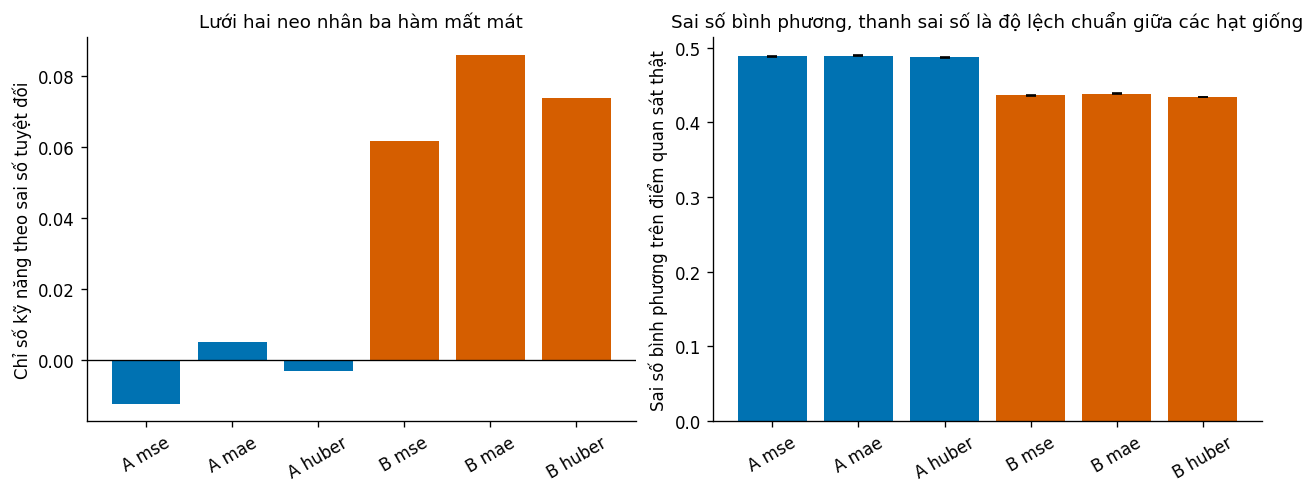

In [14]:
thu_tu = ["A_mse", "A_mae", "A_huber", "B_mse", "B_mae", "B_huber"]
nhan = [t.replace("_", " ") for t in thu_tu]
ky_nang = [TONG_HOP[t]["ky_nang_mae"] for t in thu_tu]
mse_tb = [TONG_HOP[t]["mse_trung_binh"] for t in thu_tu]
mse_sd = [TONG_HOP[t]["mse_do_lech_chuan"] for t in thu_tu]

fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.0))
mau = [PALETTE[0]] * 3 + [PALETTE[1]] * 3
ax[0].bar(nhan, ky_nang, color=mau)
ax[0].axhline(0.0, color="black", linewidth=0.8)
ax[0].set_ylabel("Chỉ số kỹ năng theo sai số tuyệt đối")
ax[0].set_title("Lưới hai neo nhân ba hàm mất mát")
ax[0].tick_params(axis="x", rotation=30)
ax[1].bar(nhan, mse_tb, yerr=mse_sd, color=mau, capsize=3)
ax[1].set_ylabel("Sai số bình phương trên điểm quan sát thật")
ax[1].set_title("Sai số bình phương, thanh sai số là độ lệch chuẩn giữa các hạt giống")
ax[1].tick_params(axis="x", rotation=30)
luu_hinh(fig, "W3_16_luoi_ba_ham_mat_mat.png")
plt.show()


## 8. Ghi kết quả

In [15]:
ket_qua = {
    "kiem_tra_luc": datetime.datetime.now().isoformat(timespec="seconds"),
    "run_tag": RUN_TAG, "read_tag": READ_TAG, "n_seeds": N_SEEDS,
    "huber_delta": HUBER_DELTA, "n_boot": N_BOOT,
    "mse_persistence": MSE_PERSISTENCE, "mae_persistence": MAE_PERSISTENCE,
    "tong_hop": TONG_HOP, "kiem_dinh": KIEM_DINH,
}
dich = RUN_DIR / "W3_ba_ham_mat_mat_hai_neo.json"
dich.write_text(json.dumps(ket_qua, ensure_ascii=False, indent=2))
print("Đã ghi", dich)
print("Ô tốt nhất theo chỉ số kỹ năng:",
      max(TONG_HOP, key=lambda k: TONG_HOP[k]["ky_nang_mae"]))


Đã ghi /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_16_ba_ham_mat_mat_hai_neo/W3_ba_ham_mat_mat_hai_neo.json
Ô tốt nhất theo chỉ số kỹ năng: B_mae
